<a href="https://colab.research.google.com/github/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution/blob/main/notebooks/01_data_setup_and_eda.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Data setup and EDA

Runs the manuscript's data steps on Colab: download the three datasets, check the folder labels,
build the 70/15/15 splits and run the EDA (section 3.5).

Before starting: **Runtime > Change runtime type > GPU** (needed later for training, not for this notebook),
and have your Kaggle API token (`kaggle.json`, from Kaggle > Settings > Create New Token) ready.

## 1. Get the code

In [2]:
BRANCH = "main"
!git clone -b $BRANCH https://github.com/Cheponke/Transformation-Aware-Reliability-Modeling-for-Multi-Signal-Synthetic-Image-Attribution.git repo
%cd repo
!pip install -q -e ".[train,dev]" kaggle

Cloning into 'repo'...
remote: Enumerating objects: 81, done.
remote: Counting objects: 100% (81/81), done.
remote: Compressing objects: 100% (64/64), done.
remote: Total 81 (delta 14), reused 71 (delta 11), pack-reused 0 (from 0)
Receiving objects: 100% (81/81), 37.64 KiB | 12.55 MiB/s, done.
Resolving deltas: 100% (14/14), done.
/content/repo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for attribution (pyproject.toml) ... done


## 2. Optional: keep the datasets on Google Drive
Skip this on the free 15 GB Drive plan: the three datasets are well over 15 GB. Without it they go on
Colab's own disk (~70 GB free) and are re-downloaded each session, which takes a few minutes.

In [3]:
from google.colab import drive
drive.mount("/content/drive")
!mkdir -p /content/drive/MyDrive/thesis-data/raw
!rm -rf data/raw && ln -s /content/drive/MyDrive/thesis-data/raw data/raw

Mounted at /content/drive


## 3. Kaggle token
On Kaggle: Settings > API Tokens > **Legacy API Credentials**. That downloads `kaggle.json`.

In [4]:
from google.colab import files
files.upload()  # choose kaggle.json
!mkdir -p ~/.kaggle && mv kaggle.json ~/.kaggle/ && chmod 600 ~/.kaggle/kaggle.json

Saving kaggle.json to kaggle.json


## 4. Download
Takes 20-40 minutes, mostly unzipping. Don't stop it partway: a stopped dataset is re-downloaded on the next run.

In [2]:
!python scripts/download_datasets.py

kannan_ai_human_art: downloading kausthubkannan/ai-and-human-art-classification -> data/raw/kannan
Dataset URL: https://www.kaggle.com/datasets/kausthubkannan/ai-and-human-art-classification
License(s): DbCL-1.0
100% 2.21G/2.21G [02:11<00:00, 18.0MB/s]

superpotato9_ai_recognition: downloading superpotato9/dalle-recognition-dataset -> data/raw/superpotato9
Dataset URL: https://www.kaggle.com/datasets/superpotato9/dalle-recognition-dataset
License(s): MIT
100% 13.4G/13.4G [13:26<00:00, 17.9MB/s]

ai_artbench: downloading ravidussilva/real-ai-art -> data/raw/ai_artbench
Dataset URL: https://www.kaggle.com/datasets/ravidussilva/real-ai-art
License(s): other
100% 9.95G/9.95G [10:13<00:00, 17.4MB/s]



## 5. Check the folder labels
Every folder should show `human` or `ai`. If any show `UNMATCHED` or the wrong label,
fix the `classes` rules for that dataset in `configs/default.yaml` and re-run this cell.

In [8]:
!python scripts/inspect_datasets.py


== kannan_ai_human_art (data/raw/kannan)
     43442  UNMATCHED  ai_art_classification/test
     10330  ai         ai_art_classification/train/AI_GENERATED
      8288  human      ai_art_classification/train/NON_AI_GENERATED

== superpotato9_ai_recognition (data/raw/superpotato9)
     17855  ai         fakeV2/fake-v2
      3780  human      real

== ai_artbench (data/raw/ai_artbench)
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_art_nouveau
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_baroque
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_expressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_impressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_post_impressionism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_realism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_renaissance
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_romanticism
      1000  ai         Real_AI_SD_LD_Dataset/test/AI_LD_surrealism
 

## 6. Build the splits

In [16]:
!python scripts/prepare_data.py

kannan_ai_human_art: 18618 labeled images, 43442 unmatched
superpotato9_ai_recognition: 21635 labeled images, 0 unmatched
ai_artbench: 185015 labeled images, 0 unmatched
sampled label 0: {'superpotato9_ai_recognition': 3333, 'kannan_ai_human_art': 3333, 'ai_artbench': 3334}
sampled label 1: {'kannan_ai_human_art': 3333, 'superpotato9_ai_recognition': 3333, 'ai_artbench': 3334}
removed 55 duplicate images (0 with conflicting labels)
train: 13961 images
val: 2992 images
test: 2992 images


In [17]:
import json
r = json.load(open("outputs/eda/report.json"))
for k, v in r["image_properties"].items(): print(k, v["formats"])

ai_artbench/label0 {'JPEG': 1010}
ai_artbench/label1 {'JPEG': 1002}
kannan_ai_human_art/label0 {'JPEG': 983}
kannan_ai_human_art/label1 {'JPEG': 1032}
superpotato9_ai_recognition/label0 {'JPEG': 965, 'PNG': 27}
superpotato9_ai_recognition/label1 {'PNG': 717, 'JPEG': 264}


## 7. EDA
Writes `outputs/eda/report.json` (class balance, image sizes, intensity/contrast, normalization
mean/std, leakage check) and `outputs/eda/per_image.csv`. Copy `train_normalization` into
`preprocess.mean` / `preprocess.std` in the config.

In [11]:
!python scripts/eda.py --max-per-split 2000

/usr/local/lib/python3.13/dist-packages/PIL/Image.py:1047: UserWarning: Palette images with Transparency expressed in bytes should be converted to RGBA images
  warnings.warn(
{
  "counts": {
    "train": 14000,
    "val": 3000,
    "test": 3000
  },
  "train_normalization": {
    "mean": [
      0.4805,
      0.4368,
      0.3864
    ],
    "std": [
      0.2829,
      0.2707,
      0.2717
    ]
  },
  "cross_split_duplicates": {
    "train+val": 13,
    "test+train": 8,
    "test+val": 1
  }
}
full report: outputs/eda/report.json


In [14]:
import json, pandas as pd
report = json.load(open("outputs/eda/report.json"))
print(json.dumps(report["class_balance"], indent=1))
print("train normalization:", report["train_normalization"])
print("cross-split duplicates:", report["cross_split_duplicates"])
df = pd.read_csv("outputs/eda/per_image.csv")
df.groupby(["source", "label"])[["width", "height", "intensity", "contrast"]].describe().T

{
 "train": {
  "overall": {
   "0": {
    "n": 7000,
    "p": 0.5
   },
   "1": {
    "n": 7000,
    "p": 0.5
   }
  },
  "by_source": {
   "ai_artbench": {
    "0": {
     "n": 2305,
     "p": 0.4933647260273973
    },
    "1": {
     "n": 2367,
     "p": 0.5066352739726028
    }
   },
   "kannan_ai_human_art": {
    "0": {
     "n": 2329,
     "p": 0.5052060737527115
    },
    "1": {
     "n": 2281,
     "p": 0.4947939262472885
    }
   },
   "superpotato9_ai_recognition": {
    "0": {
     "n": 2366,
     "p": 0.5014836795252225
    },
    "1": {
     "n": 2352,
     "p": 0.49851632047477745
    }
   }
  }
 },
 "val": {
  "overall": {
   "0": {
    "n": 1500,
    "p": 0.5
   },
   "1": {
    "n": 1500,
    "p": 0.5
   }
  },
  "by_source": {
   "ai_artbench": {
    "0": {
     "n": 529,
     "p": 0.5237623762376238
    },
    "1": {
     "n": 481,
     "p": 0.4762376237623762
    }
   },
   "kannan_ai_human_art": {
    "0": {
     "n": 494,
     "p": 0.4796116504854369
    },
    

source           ai_artbench              kannan_ai_human_art               \
label                      0            1                   0            1   
width     count  1010.000000  1002.000000          983.000000  1032.000000   
          mean    256.000000   505.357285          512.000000   512.000000   
          std       0.000000   256.041600            0.000000     0.000000   
          min     256.000000   256.000000          512.000000   512.000000   
          25%     256.000000   256.000000          512.000000   512.000000   
          50%     256.000000   256.000000          512.000000   512.000000   
          75%     256.000000   768.000000          512.000000   512.000000   
          max     256.000000   768.000000          512.000000   512.000000   
height    count  1010.000000  1002.000000          983.000000  1032.000000   
          mean    256.000000   505.357285          512.000000   512.000000   
          std       0.000000   256.041600            0.000000     0.000000   
          min     256.000000   256.000000          512.000000   512.000000   
          25%     256.000000   256.000000          512.000000   512.000000   
          50%     256.000000   256.000000          512.000000   512.000000   
          75%     256.000000   768.000000          512.000000   512.000000   
          max     256.000000   768.000000          512.000000   512.000000   
intensity count  1010.000000  1002.000000          983.000000  1032.000000   
          mean      0.462547     0.427991            0.473971     0.424731   
          std       0.161078     0.069607            0.170628     0.115337   
          min       0.086955     0.199654            0.086156     0.086560   
          25%       0.336725     0.385080            0.348363     0.355101   
          50%       0.456971     0.430868            0.465767     0.419502   
          75%       0.579576     0.472943            0.592926     0.480514   
          max       0.908032     0.667642            0.965209     0.899785   
contrast  count  1010.000000  1002.000000          983.000000  1032.000000   
          mean      0.188743     0.204774            0.197749     0.242322   
          std       0.057449     0.048208            0.059412     0.058586   
          min       0.023601     0.092163            0.014695     0.079899   
          25%       0.150804     0.171173            0.159760     0.200565   
          50%       0.186028     0.199130            0.195733     0.243133   
          75%       0.222167     0.226395            0.234070     0.281968   
          max       0.458439     0.407408            0.407280     0.409171   

source          superpotato9_ai_recognition               
label                                     0            1  
width     count                  992.000000   981.000000  
          mean                   687.110887  1197.228338  
          std                   1071.725326   609.181362  
          min                    224.000000   373.000000  
          25%                    224.000000  1024.000000  
          50%                    224.000000  1024.000000  
          75%                    224.000000  1312.000000  
          max                   9921.000000  6720.000000  
height    count                  992.000000   981.000000  
          mean                   723.759073  1176.240571  
          std                   1144.236029   607.773136  
          min                    224.000000   320.000000  
          25%                    224.000000  1024.000000  
          50%                    224.000000  1024.000000  
          75%                    224.000000  1208.000000  
          max                  10803.000000  6720.000000  
intensity count                  992.000000   981.000000  
          mean                     0.482886     0.396278  
          std                      0.165134     0.153762  
          min                      0.014376     0.082382  
          25%                      0.380928     0

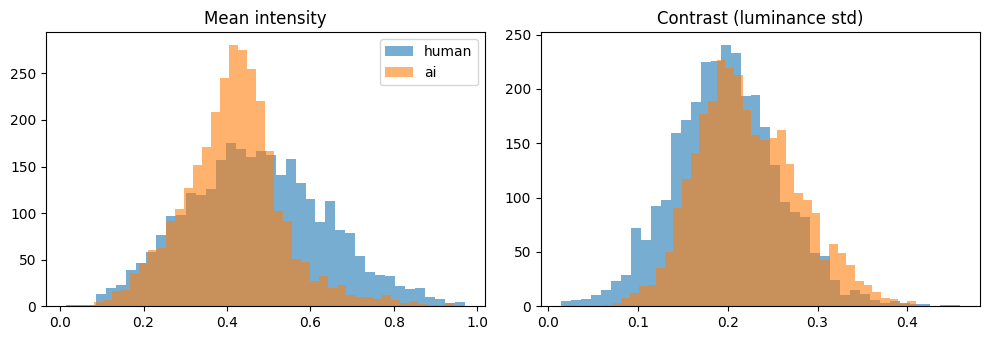

In [13]:
import matplotlib.pyplot as plt
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for label, name in [(0, "human"), (1, "ai")]:
    d = df[df.label == label]
    axes[0].hist(d.intensity, bins=40, alpha=0.6, label=name)
    axes[1].hist(d.contrast, bins=40, alpha=0.6, label=name)
axes[0].set_title("Mean intensity"); axes[1].set_title("Contrast (luminance std)")
axes[0].legend(); plt.tight_layout()